In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
import torchvision
import torchvision.transforms as transforms
import os
import argparse
from pathlib import Path
import re
import random
import math
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import os
from tqdm.auto import tqdm
import pycwt as wavelet
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
! pip install pycwt

### WTC based on LI

WTC setup:
  Seeds S      : 100
  N, T, D      : 36 8640 2
  n_scales     : 145
  freq range   : 2.363313743150369e-05 to 0.09680133091943911 Hz
  period range : 10.330436477492537 to 42313.46781180943 sec
Loaded GT FULL WTC from: /content/drive/MyDrive/aim3/wtc_maps_12h_windows_only.npz

GT validity check:
  total segments         : 36
  WTC finite valid       : 36
  WTC >=0 valid          : 36
  WTC <=1 valid          : 36
  COI finite valid       : 36
  COI positive valid     : 36
  final valid GT segments: 36
  invalid GT segments    : 0
Saved GT validity CSV: /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/gt_full_wtc_validity.csv

Processing seed index 0 | seed value 1337


WI seed 1337:   0%|          | 0/36 [00:00<?, ?it/s]

Full WTC seed 1337:   0%|          | 0/36 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_eval_seed_000.npz

Processing seed index 1 | seed value 1338


WI seed 1338:   0%|          | 0/36 [00:00<?, ?it/s]

Full WTC seed 1338:   0%|          | 0/36 [00:00<?, ?it/s]

... (292 outputs left out)

Saved: /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_eval_seed_098.npz

Processing seed index 99 | seed value 1436


WI seed 1436:   0%|          | 0/36 [00:00<?, ?it/s]

Full WTC seed 1436:   0%|          | 0/36 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_eval_seed_099.npz

Saved:
  GT validity CSV: /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/gt_full_wtc_validity.csv
  all rows CSV   : /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_metrics_all_segments_all_100seeds.csv
  summary CSV    : /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_summary_by_seed_100seeds.csv
  all arrays     : /content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_metrics_arrays_all_100seeds.npz

Shapes:
  valid_idx count       : 36
  full_wtc_coi_mae      : (100, 36)
  full_wtc_coi_mape     : (100, 36)
  full_wtc_coi_ssim     : (100, 36)
  n_valid_pixels_in_coi : (100, 36)

Find highest FULL-WTC-in-COI MAPE row and plot exact pair

Highest MAPE row:
seed_index      

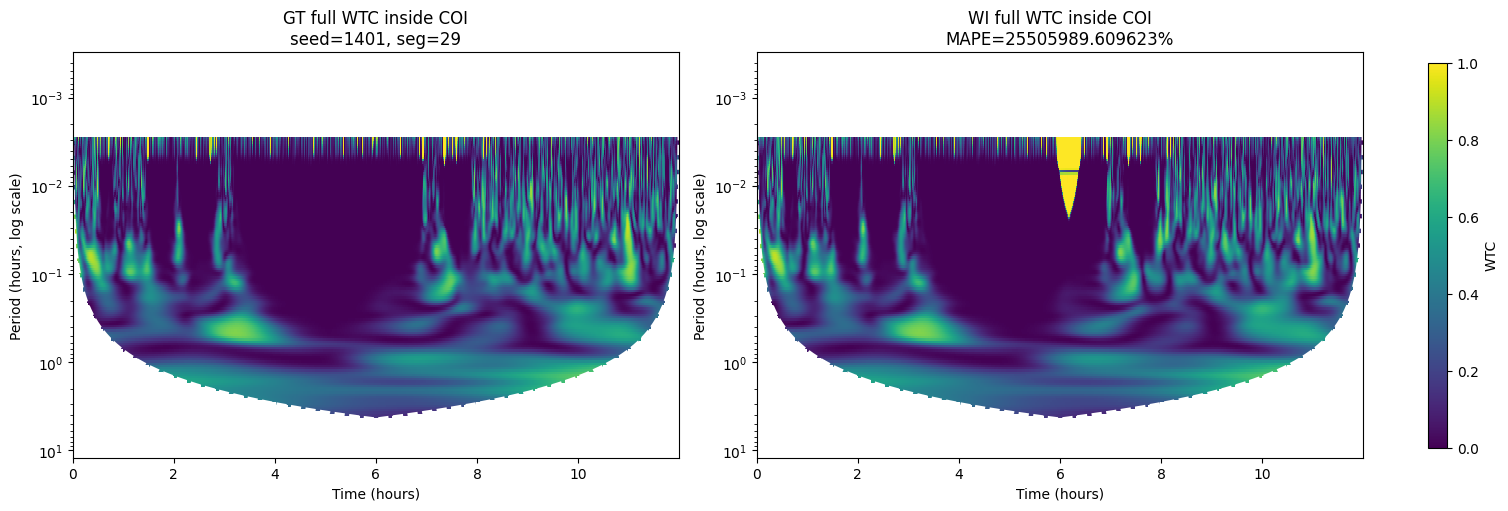

In [ ]:
# ============================================================
# Evaluate weighted interpolation using FULL WTC inside COI
# ------------------------------------------------------------
# Input:
#   GAP_NPZ     : artificial gaps NPZ with 100 seeds
#   GT_WTC_NPZ  : clean full-WTC NPZ
#
# Output:
#   per-seed NPZs
#   pooled CSV / NPZ summaries
#   plot of the worst-MAPE example
# ============================================================

GAP_NPZ = "/content/drive/MyDrive/aim3/artificial_gaps_36segments_100seeds.npz"
GT_WTC_NPZ = "/content/drive/MyDrive/aim3/wtc_maps_12h_windows_only.npz"
OUT_DIR = "/content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI"
os.makedirs(OUT_DIR, exist_ok=True)

# -----------------------------
# WTC settings
# -----------------------------
DT = 5.0
DJ = 1 / 12
S0 = 2 * DT
WAVELET_NAME = "morlet"
EPS = 1e-8

# ============================================================
# Helpers
# ============================================================
def weighted_linear_interpolation(left_val, right_val, dist_left, dist_right):
    denom = dist_left + dist_right
    if denom <= 0:
        return 0.5 * (left_val + right_val)
    return (dist_right * left_val + dist_left * right_val) / denom


def weighted_interpolate_1d(x_in_1d, m_hat_1d):
    """
    x_in_1d : (T,)
    m_hat_1d: (T,) 1=observed, 0=missing
    """
    x = np.asarray(x_in_1d, dtype=np.float32).copy()
    m = (np.asarray(m_hat_1d) > 0.5).astype(np.int32)

    x = np.nan_to_num(x, nan=0.0)
    T = len(x)

    t = 0
    while t < T:
        if m[t] == 1:
            t += 1
            continue

        start = t
        while t + 1 < T and m[t + 1] == 0:
            t += 1
        end = t

        left_idx = start - 1 if start - 1 >= 0 and m[start - 1] == 1 else None
        right_idx = end + 1 if end + 1 < T and m[end + 1] == 1 else None

        if left_idx is not None and right_idx is not None:
            left_val = float(x[left_idx])
            right_val = float(x[right_idx])

            for k in range(start, end + 1):
                dist_left = float(k - left_idx)
                dist_right = float(right_idx - k)
                x[k] = weighted_linear_interpolation(
                    left_val=left_val,
                    right_val=right_val,
                    dist_left=dist_left,
                    dist_right=dist_right,
                )

        elif left_idx is not None:
            x[start:end + 1] = float(x[left_idx])

        elif right_idx is not None:
            x[start:end + 1] = float(x[right_idx])

        else:
            x[start:end + 1] = 0.0

        t += 1

    return x.astype(np.float32)


def weighted_interpolate_sample(x_gapped_sample, m_hat_sample):
    """
    x_gapped_sample : (T,D)
    m_hat_sample    : (T,D), 1=observed, 0=missing
    """
    T, D = x_gapped_sample.shape
    out = np.zeros((T, D), dtype=np.float32)
    for d in range(D):
        out[:, d] = weighted_interpolate_1d(
            x_in_1d=x_gapped_sample[:, d],
            m_hat_1d=m_hat_sample[:, d]
        )
    return out


def build_coi_mask(periods_sec, coi_sec_1d):
    """
    periods_sec : (S,)
    coi_sec_1d  : (T,)
    Returns mask shape (S,T), True = inside COI
    """
    periods_sec = np.asarray(periods_sec, dtype=np.float64)
    coi_sec_1d = np.asarray(coi_sec_1d, dtype=np.float64)
    return periods_sec[:, None] <= coi_sec_1d[None, :]


def masked_mae(gt_map, pred_map, mask):
    gt = np.asarray(gt_map, dtype=np.float64)
    pr = np.asarray(pred_map, dtype=np.float64)
    m = np.asarray(mask, dtype=bool)

    if m.sum() == 0:
        return np.nan
    return float(np.mean(np.abs(gt[m] - pr[m])))


def masked_mape(gt_map, pred_map, mask, eps=1e-8):
    gt = np.asarray(gt_map, dtype=np.float64)
    pr = np.asarray(pred_map, dtype=np.float64)
    m = np.asarray(mask, dtype=bool)

    if m.sum() == 0:
        return np.nan

    denom = np.maximum(np.abs(gt[m]), eps)
    return float(100.0 * np.mean(np.abs(gt[m] - pr[m]) / denom))


def masked_ssim_bbox(gt_map, pred_map, mask):
    """
    SSIM on the bounding box of the valid mask.
    Outside-mask pixels are zeroed before SSIM.
    """
    gt = np.asarray(gt_map, dtype=np.float32)
    pr = np.asarray(pred_map, dtype=np.float32)
    m = np.asarray(mask, dtype=bool)

    if m.sum() < 2:
        return np.nan

    rows, cols = np.where(m)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1

    gt_crop = gt[r0:r1, c0:c1].copy()
    pr_crop = pr[r0:r1, c0:c1].copy()
    m_crop = m[r0:r1, c0:c1]

    gt_crop[~m_crop] = 0.0
    pr_crop[~m_crop] = 0.0

    return float(ssim(gt_crop, pr_crop, data_range=1.0))


# ============================================================
# WTC setup
# ============================================================
if WAVELET_NAME.lower() == "morlet":
    mother = wavelet.Morlet(6)
else:
    raise ValueError(f"Unsupported wavelet: {WAVELET_NAME}")

gap_data = np.load(GAP_NPZ, allow_pickle=True)

X_clean_all = gap_data["X"].astype(np.float32)         # [N,T,D]
X_gapped_all = gap_data["X_in"].astype(np.float32)     # [S,N,T,D]
M_hat_all = gap_data["M_hat"].astype(np.uint8)         # [S,N,T,D]
I_all = gap_data["I"].astype(np.uint8)                 # [S,N,T,D]
patient_ids = gap_data["patient_ids"]
filenames = np.array([str(x) for x in gap_data["filenames"].tolist()])
seed_values = gap_data["seed_values"].astype(np.int32)

N, T, D = X_clean_all.shape
S = X_gapped_all.shape[0]

assert X_gapped_all.shape == (S, N, T, D)
assert M_hat_all.shape == (S, N, T, D)
assert I_all.shape == (S, N, T, D)

J = int(np.floor(np.log2(T * DT / S0) / DJ))
scales = S0 * 2 ** (np.arange(0, J + 1) * DJ)
periods_sec = scales * mother.flambda()
freqs_hz = 1.0 / periods_sec

print("WTC setup:")
print("  Seeds S      :", S)
print("  N, T, D      :", N, T, D)
print("  n_scales     :", len(scales))
print("  freq range   :", float(freqs_hz.min()), "to", float(freqs_hz.max()), "Hz")
print("  period range :", float(periods_sec.min()), "to", float(periods_sec.max()), "sec")


def compute_wct_single(x, y):
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)

    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError("Non-finite raw signal passed into compute_wct_single")

    out = wavelet.wct(
        x, y,
        dt=DT,
        dj=DJ,
        s0=S0,
        J=J,
        wavelet=mother,
        sig=False
    )

    WCT = np.asarray(out[0], dtype=np.float64)
    if np.iscomplexobj(WCT):
        WCT = np.abs(WCT)

    coi = None
    for arr in out[1:]:
        arr = np.asarray(arr)
        if arr.ndim == 1 and arr.shape[0] == T:
            coi = arr.astype(np.float32)
            break

    if coi is None:
        raise ValueError("Could not identify COI from pycwt.wct output.")

    return WCT.astype(np.float32), coi.astype(np.float32)


# ============================================================
# Load GT FULL WTC + COI
# ============================================================
if os.path.exists(GT_WTC_NPZ):
    gt_data = np.load(GT_WTC_NPZ, allow_pickle=True)

    needed = ["wtc_full", "coi_sec", "periods_full_sec", "freqs_full_hz"]
    for k in needed:
        if k not in gt_data.files:
            raise ValueError(f"{GT_WTC_NPZ} missing required key: {k}")

    gt_wtc_full = gt_data["wtc_full"].astype(np.float32)        # [N,S,T]
    gt_coi_sec = gt_data["coi_sec"].astype(np.float32)          # [N,T]
    periods_full_sec_saved = gt_data["periods_full_sec"].astype(np.float32)
    freqs_full_hz_saved = gt_data["freqs_full_hz"].astype(np.float32)

    print("Loaded GT FULL WTC from:", GT_WTC_NPZ)

    if gt_wtc_full.shape != (N, len(scales), T):
        raise ValueError(
            f"GT full WTC shape mismatch. Expected {(N, len(scales), T)}, got {gt_wtc_full.shape}"
        )

    if gt_coi_sec.shape != (N, T):
        raise ValueError(
            f"GT coi_sec shape mismatch. Expected {(N, T)}, got {gt_coi_sec.shape}"
        )

    if len(periods_full_sec_saved) != len(scales):
        raise ValueError("periods_full_sec length mismatch with current scales.")
else:
    print("GT WTC NPZ not found. Computing GT full WTC from clean signals.")
    gt_wtc_full = np.zeros((N, len(scales), T), dtype=np.float32)
    gt_coi_sec = np.zeros((N, T), dtype=np.float32)

    for i in tqdm(range(N), desc="Computing GT full WTC"):
        WCT, coi = compute_wct_single(X_clean_all[i, :, 0], X_clean_all[i, :, 1])
        gt_wtc_full[i] = WCT
        gt_coi_sec[i] = coi

# ============================================================
# GT validity check for FULL WTC
# ============================================================
gt_all_finite = np.isfinite(gt_wtc_full).all(axis=(1, 2))
gt_all_ge0 = (gt_wtc_full >= 0).all(axis=(1, 2))
gt_all_le1 = (gt_wtc_full <= 1).all(axis=(1, 2))
gt_coi_finite = np.isfinite(gt_coi_sec).all(axis=1)
gt_coi_pos = (gt_coi_sec > 0).all(axis=1)

valid_gt_mask = gt_all_finite & gt_all_ge0 & gt_all_le1 & gt_coi_finite & gt_coi_pos
valid_idx = np.where(valid_gt_mask)[0]
invalid_idx = np.where(~valid_gt_mask)[0]

print("\nGT validity check:")
print("  total segments         :", len(gt_wtc_full))
print("  WTC finite valid       :", gt_all_finite.sum())
print("  WTC >=0 valid          :", gt_all_ge0.sum())
print("  WTC <=1 valid          :", gt_all_le1.sum())
print("  COI finite valid       :", gt_coi_finite.sum())
print("  COI positive valid     :", gt_coi_pos.sum())
print("  final valid GT segments:", len(valid_idx))
print("  invalid GT segments    :", len(invalid_idx))

if len(valid_idx) == 0:
    raise ValueError("No valid GT full WTC maps remain after filtering.")

gt_validity_csv = os.path.join(OUT_DIR, "gt_full_wtc_validity.csv")
pd.DataFrame({
    "segment_idx": np.arange(len(gt_wtc_full)),
    "gt_all_finite": gt_all_finite.astype(int),
    "gt_all_ge0": gt_all_ge0.astype(int),
    "gt_all_le1": gt_all_le1.astype(int),
    "gt_coi_finite": gt_coi_finite.astype(int),
    "gt_coi_pos": gt_coi_pos.astype(int),
    "gt_valid": valid_gt_mask.astype(int),
}).to_csv(gt_validity_csv, index=False)
print("Saved GT validity CSV:", gt_validity_csv)

# ============================================================
# Process all seeds
# ============================================================
all_rows = []
mae_all = []
mape_all = []
ssim_all = []
n_valid_pixels_all = []

for s in range(S):
    seed_id = int(seed_values[s])
    print(f"\nProcessing seed index {s} | seed value {seed_id}")

    X_gapped = X_gapped_all[s]
    M_hat = M_hat_all[s]

    # ----------------------------------------
    # Weighted interpolation
    # ----------------------------------------
    X_wi = np.zeros_like(X_clean_all, dtype=np.float32)

    for i in tqdm(range(N), desc=f"WI seed {seed_id}"):
        X_wi[i] = weighted_interpolate_sample(
            x_gapped_sample=X_gapped[i],
            m_hat_sample=M_hat[i]
        )

    # ----------------------------------------
    # FULL WTC on WI-filled signals
    # ----------------------------------------
    wtc_full_pred = np.zeros((N, len(scales), T), dtype=np.float32)
    coi_pred_all = np.zeros((N, T), dtype=np.float32)

    for i in tqdm(range(N), desc=f"Full WTC seed {seed_id}"):
        WCT, coi = compute_wct_single(X_wi[i, :, 0], X_wi[i, :, 1])
        WCT = np.nan_to_num(WCT, nan=0.0, posinf=1.0, neginf=0.0)
        WCT = np.clip(WCT, 0.0, 1.0)

        coi = np.nan_to_num(
            coi,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

        wtc_full_pred[i] = WCT
        coi_pred_all[i] = coi

    # ----------------------------------------
    # Restrict to valid GT segments
    # ----------------------------------------
    patient_ids_valid = patient_ids[valid_idx]
    filenames_valid = filenames[valid_idx]
    X_wi_valid = X_wi[valid_idx]
    wtc_full_gt_valid = gt_wtc_full[valid_idx]
    wtc_full_pred_valid = wtc_full_pred[valid_idx]
    gt_coi_valid = gt_coi_sec[valid_idx]
    coi_pred_valid = coi_pred_all[valid_idx]

    # ----------------------------------------
    # Metrics per valid segment, using FULL WTC inside GT COI
    # ----------------------------------------
    n_valid = len(valid_idx)
    mae_seed = np.zeros(n_valid, dtype=np.float32)
    mape_seed = np.zeros(n_valid, dtype=np.float32)
    ssim_seed = np.zeros(n_valid, dtype=np.float32)
    n_valid_pixels_seed = np.zeros(n_valid, dtype=np.int32)

    for j, i_global in enumerate(valid_idx):
        gt_map = gt_wtc_full[i_global]
        pr_map = wtc_full_pred[i_global]

        coi_mask = build_coi_mask(periods_sec, gt_coi_sec[i_global])
        valid_mask = coi_mask

        n_valid_pixels = int(valid_mask.sum())
        mae_i = masked_mae(gt_map, pr_map, valid_mask)
        mape_i = masked_mape(gt_map, pr_map, valid_mask, eps=EPS)
        ssim_i = masked_ssim_bbox(gt_map, pr_map, valid_mask)

        mae_seed[j] = mae_i
        mape_seed[j] = mape_i
        ssim_seed[j] = ssim_i
        n_valid_pixels_seed[j] = n_valid_pixels

        all_rows.append({
            "seed_index": int(s),
            "seed": int(seed_id),
            "segment_idx_original": int(i_global),
            "segment_idx_valid_order": int(j),
            "patient_id": str(patient_ids[i_global]),
            "filename": str(filenames[i_global]),
            "n_valid_pixels_in_coi": int(n_valid_pixels),
            "full_wtc_coi_mae": float(mae_i),
            "full_wtc_coi_mape": float(mape_i),
            "full_wtc_coi_ssim": float(ssim_i),
        })

    mae_all.append(mae_seed)
    mape_all.append(mape_seed)
    ssim_all.append(ssim_seed)
    n_valid_pixels_all.append(n_valid_pixels_seed)

    # ----------------------------------------
    # Save per-seed NPZ
    # ----------------------------------------
    out_npz = os.path.join(
        OUT_DIR,
        f"weightedinterp_fullWTC_inCOI_eval_seed_{s:03d}.npz"
    )
    np.savez_compressed(
        out_npz,
        valid_idx=valid_idx.astype(np.int32),
        gt_valid_mask=valid_gt_mask.astype(np.uint8),

        X_wi=X_wi_valid.astype(np.float32),

        wtc_full_gt=wtc_full_gt_valid.astype(np.float32),
        wtc_full_pred=wtc_full_pred_valid.astype(np.float32),

        gt_coi_sec=gt_coi_valid.astype(np.float32),
        pred_coi_sec=coi_pred_valid.astype(np.float32),

        full_wtc_coi_mae=mae_seed.astype(np.float32),
        full_wtc_coi_mape=mape_seed.astype(np.float32),
        full_wtc_coi_ssim=ssim_seed.astype(np.float32),
        n_valid_pixels_in_coi=n_valid_pixels_seed.astype(np.int32),

        patient_ids=patient_ids_valid,
        filenames=filenames_valid,

        seed_index=np.array([s], dtype=np.int32),
        seed=np.array([seed_id], dtype=np.int32),

        dt_sec=np.array([DT], dtype=np.float32),
        dj=np.array([DJ], dtype=np.float32),
        s0=np.array([S0], dtype=np.float32),
        J=np.array([J], dtype=np.int32),

        scales=scales.astype(np.float32),
        freqs_full_hz=freqs_hz.astype(np.float32),
        periods_full_sec=periods_sec.astype(np.float32),
        eps=np.array([EPS], dtype=np.float32),
    )
    print("Saved:", out_npz)

# ============================================================
# Save pooled results
# ============================================================
mae_all = np.stack(mae_all, axis=0)                # [S, n_valid]
mape_all = np.stack(mape_all, axis=0)
ssim_all = np.stack(ssim_all, axis=0)
n_valid_pixels_all = np.stack(n_valid_pixels_all, axis=0)

rows_df = pd.DataFrame(all_rows)
rows_csv = os.path.join(OUT_DIR, "weightedinterp_fullWTC_inCOI_metrics_all_segments_all_100seeds.csv")
rows_df.to_csv(rows_csv, index=False)

summary_df = (
    rows_df.groupby("seed", as_index=False)
    .agg(
        full_wtc_coi_mae_mean=("full_wtc_coi_mae", "mean"),
        full_wtc_coi_mae_std=("full_wtc_coi_mae", "std"),
        full_wtc_coi_mape_mean=("full_wtc_coi_mape", "mean"),
        full_wtc_coi_mape_std=("full_wtc_coi_mape", "std"),
        full_wtc_coi_ssim_mean=("full_wtc_coi_ssim", "mean"),
        full_wtc_coi_ssim_std=("full_wtc_coi_ssim", "std"),
        n_valid_pixels_mean=("n_valid_pixels_in_coi", "mean"),
        n_segments=("segment_idx_valid_order", "count"),
    )
)
summary_csv = os.path.join(OUT_DIR, "weightedinterp_fullWTC_inCOI_summary_by_seed_100seeds.csv")
summary_df.to_csv(summary_csv, index=False)

all_npz = os.path.join(OUT_DIR, "weightedinterp_fullWTC_inCOI_metrics_arrays_all_100seeds.npz")
np.savez_compressed(
    all_npz,
    valid_idx=valid_idx.astype(np.int32),
    gt_valid_mask=valid_gt_mask.astype(np.uint8),
    seed_values=seed_values.astype(np.int32),
    n_valid_pixels_in_coi=n_valid_pixels_all.astype(np.int32),
    full_wtc_coi_mae=mae_all.astype(np.float32),
    full_wtc_coi_mape=mape_all.astype(np.float32),
    full_wtc_coi_ssim=ssim_all.astype(np.float32),
)

print("\nSaved:")
print("  GT validity CSV:", gt_validity_csv)
print("  all rows CSV   :", rows_csv)
print("  summary CSV    :", summary_csv)
print("  all arrays     :", all_npz)

print("\nShapes:")
print("  valid_idx count       :", len(valid_idx))
print("  full_wtc_coi_mae      :", mae_all.shape)
print("  full_wtc_coi_mape     :", mape_all.shape)
print("  full_wtc_coi_ssim     :", ssim_all.shape)
print("  n_valid_pixels_in_coi :", n_valid_pixels_all.shape)

# ============================================================
# Find highest MAPE row and plot exact GT / WI pair
# ============================================================
print("\n" + "=" * 70)
print("Find highest FULL-WTC-in-COI MAPE row and plot exact pair")
print("=" * 70)

rows_df = pd.read_csv(rows_csv)
rows_df = rows_df[np.isfinite(rows_df["full_wtc_coi_mape"])].copy()

worst_row = rows_df.loc[rows_df["full_wtc_coi_mape"].idxmax()]
print("\nHighest MAPE row:")
print(worst_row)

seed_index = int(worst_row["seed_index"])
seed_id = int(worst_row["seed"])
j_valid = int(worst_row["segment_idx_valid_order"])
i_global = int(worst_row["segment_idx_original"])

seed_npz_path = os.path.join(
    OUT_DIR,
    f"weightedinterp_fullWTC_inCOI_eval_seed_{seed_index:03d}.npz"
)

print("\nLoading exact NPZ:", seed_npz_path)
pair_data = np.load(seed_npz_path, allow_pickle=True)

gt_map = pair_data["wtc_full_gt"][j_valid].astype(np.float64)
pred_map = pair_data["wtc_full_pred"][j_valid].astype(np.float64)
gt_coi_1d = pair_data["gt_coi_sec"][j_valid].astype(np.float64)

coi_mask = build_coi_mask(periods_sec, gt_coi_1d)
valid_mask = coi_mask

pair_mae = masked_mae(gt_map, pred_map, valid_mask)
pair_mape = masked_mape(gt_map, pred_map, valid_mask, eps=EPS)
pair_ssim = masked_ssim_bbox(gt_map, pred_map, valid_mask)

print("\nVerification:")
print(f"PAIR MAE : {pair_mae:.12f}")
print(f"PAIR MAPE: {pair_mape:.12f}")
print(f"PAIR SSIM: {pair_ssim:.12f}")

# zero outside COI for display
gt_disp = gt_map.copy()
pred_disp = pred_map.copy()
gt_disp[~valid_mask] = np.nan
pred_disp[~valid_mask] = np.nan

time_hours = np.arange(T) * DT / 3600.0
period_hours = periods_sec / 3600.0

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

vmin = np.nanmin([gt_disp, pred_disp])
vmax = np.nanmax([gt_disp, pred_disp])

im0 = axes[0].pcolormesh(
    time_hours, period_hours, gt_disp,
    shading="auto", vmin=vmin, vmax=vmax
)
axes[0].plot(time_hours, gt_coi_1d / 3600.0, "w--", linewidth=2)
axes[0].set_yscale("log")
axes[0].invert_yaxis()
axes[0].set_title(f"GT full WTC inside COI\nseed={seed_id}, seg={i_global}")
axes[0].set_xlabel("Time (hours)")
axes[0].set_ylabel("Period (hours, log scale)")

im1 = axes[1].pcolormesh(
    time_hours, period_hours, pred_disp,
    shading="auto", vmin=vmin, vmax=vmax
)
axes[1].plot(time_hours, gt_coi_1d / 3600.0, "w--", linewidth=2)
axes[1].set_yscale("log")
axes[1].invert_yaxis()
axes[1].set_title(f"WI full WTC inside COI\nMAPE={pair_mape:.6f}%")
axes[1].set_xlabel("Time (hours)")
axes[1].set_ylabel("Period (hours, log scale)")

cbar = fig.colorbar(im1, ax=axes.ravel().tolist(), shrink=0.95)
cbar.set_label("WTC")

plt.show()

In [ ]:
csv_path = "/content/drive/MyDrive/aim3/wtc_weightedinterp_eval_100seeds_fullWTC_inCOI/weightedinterp_fullWTC_inCOI_metrics_all_segments_all_100seeds.csv"
df = pd.read_csv(csv_path)
df = df[np.isfinite(df["full_wtc_coi_mae"]) & np.isfinite(df["full_wtc_coi_ssim"])].copy()
print("n rows:", len(df))
print("Mean MAE :", df["full_wtc_coi_mae"].mean())
print("Std  MAE :", df["full_wtc_coi_mae"].std())
print("Mean SSIM:", df["full_wtc_coi_ssim"].mean())
print("Std  SSIM:", df["full_wtc_coi_ssim"].std())

n rows: 3600
Mean MAE : 0.08620856339639842
Std  MAE : 0.03705300680474328
Mean SSIM: 0.7506244049867461
Std  SSIM: 0.09976084528291931
